# Machine Learning — Notebook 14
## Model Selection, Regularization & Applied ML Workshop

**Program:** Data Science & Artificial Intelligence  
**Business Case:** AdventureWorks — Return Risk Intelligence  
**Level:** Applied Machine Learning  
**Estimated classroom time:** 5–6 hours

---

### Workshop overview

In this workshop, we bring together the modeling skills developed throughout the machine learning module. We will compare candidate models, control overfitting with regularization, select hyperparameters with cross-validation, and make a final decision using evidence from an untouched test set.

The business objective is to identify orders that are likely to be returned so that the operations team can prioritize appropriate checks before dispatch.

**Learning outcomes**

By the end of this notebook, you will be able to:

- distinguish model parameters from hyperparameters;
- explain underfitting, overfitting, and the bias–variance trade-off;
- use regularization to control model complexity;
- compare different model families with a consistent validation strategy;
- build preprocessing and modeling workflows with `Pipeline`;
- tune hyperparameters using `GridSearchCV` and `RandomizedSearchCV`;
- select a model using business-relevant metrics and practical constraints;
- evaluate the selected model once on a held-out test set;
- communicate a model recommendation and its limitations.

## Contents

1. Business problem and modeling protocol
2. Prepare the AdventureWorks dataset
3. Establish a baseline
4. Model complexity, underfitting, and overfitting
5. Regularization: L1 and L2
6. Build leakage-safe modeling pipelines
7. Compare candidate models with cross-validation
8. Hyperparameter optimization
9. Select and evaluate the final model
10. Turn model scores into operational decisions
11. Applied workshop challenge
12. Summary and readiness checklist

## 1. Business problem and modeling protocol

AdventureWorks wants to identify orders with an elevated probability of being returned. The operations team can use a risk score to prioritize manual checks, confirm product details, or review delivery information.

This is a **binary classification** problem:

- `0` — the order was not returned;
- `1` — the order was returned.

A useful model must do more than achieve a high score on historical data. It should generalize to new orders, identify enough returned orders to be useful, and avoid creating an unmanageable number of false alerts.

### The modeling protocol

We will use three distinct roles for the data:

| Data portion | Purpose | How it is used |
|---|---|---|
| Training data | Learn model parameters | Fit candidate models |
| Cross-validation folds | Compare and tune candidates | Select model families and hyperparameters |
| Test data | Final, unbiased assessment | Used once after selection |

The test set must not guide feature choices, hyperparameter tuning, or threshold selection. Repeatedly checking it turns it into another validation set and makes the final estimate optimistic.

### 1.1 Set up the environment

The notebook uses standard Python data science libraries and scikit-learn estimators. All data will be generated locally, so no external file or API key is required.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV,
    RandomizedSearchCV
)
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, RocCurveDisplay, PrecisionRecallDisplay
)
from scipy.stats import randint

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)

## 2. Prepare the AdventureWorks dataset

### 2.1 Data dictionary

The dataset represents historical order-level records. The fields are intentionally limited to operational signals that could reasonably be available when an order is being reviewed.

| Feature | Description | Data type |
|---|---|---|
| `order_value` | Total value of the order | Numeric |
| `items_count` | Number of items in the order | Numeric |
| `discount_rate` | Discount applied to the order | Numeric |
| `delivery_days` | Time between dispatch and delivery | Numeric |
| `customer_orders` | Number of previous orders placed by the customer | Numeric |
| `customer_tenure_months` | Customer relationship length | Numeric |
| `payment_method` | Payment method used | Categorical |
| `shipping_type` | Shipping service selected | Categorical |
| `product_category` | Main product category | Categorical |
| `return_risk` | Whether the order was returned | Target |

For this teaching dataset, all listed predictors are assumed to be known at the time the risk assessment is made. In a real project, confirm this timing with the business team. A variable recorded after a return occurs must not be used to predict that return.

### 2.2 Generate reproducible synthetic data

The following generator creates a realistic teaching dataset with mixed numeric and categorical features. The target is influenced by several operational signals and a small amount of random variation.

Synthetic data is useful for learning a workflow, but its performance results are not evidence of real-world business performance.

In [2]:
rng = np.random.default_rng(RANDOM_STATE)
n_samples = 3000

order_value = np.clip(rng.gamma(shape=2.2, scale=65, size=n_samples), 15, 650)
items_count = rng.integers(1, 9, size=n_samples)
discount_rate = rng.choice([0.00, 0.05, 0.10, 0.15, 0.20, 0.25],
                           size=n_samples, p=[0.25, 0.15, 0.20, 0.18, 0.14, 0.08])
delivery_days = np.clip(rng.normal(3.8, 1.8, n_samples), 1, 12).round(0)
customer_orders = np.clip(rng.poisson(5, n_samples), 0, 30)
customer_tenure_months = np.clip(rng.gamma(2.0, 10, n_samples), 1, 96).round(0)

payment_method = rng.choice(
    ["Credit Card", "Debit Card", "PayPal", "Bank Transfer"],
    size=n_samples, p=[0.48, 0.22, 0.22, 0.08]
)
shipping_type = rng.choice(
    ["Standard", "Express", "Same Day"],
    size=n_samples, p=[0.62, 0.30, 0.08]
)
product_category = rng.choice(
    ["Electronics", "Home", "Accessories"],
    size=n_samples, p=[0.42, 0.33, 0.25]
)

# A hidden business process creates return probability.
logit = (
    -2.25
    + 0.0030 * (order_value - 120)
    + 0.22 * (items_count - 2)
    + 3.2 * discount_rate
    + 0.16 * (delivery_days - 3)
    - 0.035 * customer_orders
    - 0.012 * customer_tenure_months
    + np.where(payment_method == "Bank Transfer", 0.35, 0)
    + np.where(shipping_type == "Same Day", 0.20, 0)
    + np.where(product_category == "Electronics", 0.25, 0)
)
return_probability = 1 / (1 + np.exp(-logit))
return_risk = rng.binomial(1, return_probability)

orders = pd.DataFrame({
    "order_value": order_value.round(2),
    "items_count": items_count,
    "discount_rate": discount_rate,
    "delivery_days": delivery_days.astype(int),
    "customer_orders": customer_orders,
    "customer_tenure_months": customer_tenure_months,
    "payment_method": payment_method,
    "shipping_type": shipping_type,
    "product_category": product_category,
    "return_risk": return_risk
})

orders.insert(0, "order_id", [f"AW-{50001 + i}" for i in range(n_samples)])
orders.head()

,order_id,order_value,items_count,discount_rate,delivery_days,customer_orders,customer_tenure_months,payment_method,shipping_type,product_category,return_risk
0,AW-50001,150.46,7,0.10,7,7,10.0,Credit Card,Standard,Electronics,0
1,AW-50002,200.93,6,0.15,5,6,33.0,Credit Card,Express,Accessories,0
2,AW-50003,133.04,6,0.05,3,5,11.0,Debit Card,Standard,Electronics,0
3,AW-50004,119.85,5,0.15,2,7,23.0,Credit Card,Express,Accessories,0
4,AW-50005,217.38,6,0.10,6,6,50.0,Credit Card,Express,Home,0


In [3]:
print(f"Dataset shape: {orders.shape}")
print(f"Returned orders: {orders['return_risk'].sum():,}")
print(f"Return rate: {orders['return_risk'].mean():.1%}")
display(orders.dtypes.rename("data_type").to_frame())
display(orders.describe(include="all").T)

Dataset shape: (3000, 11)
Returned orders: 613
Return rate: 20.4%


,data_type
order_id,object
order_value,float64
items_count,int64
discount_rate,float64
delivery_days,int64
customer_orders,int64
customer_tenure_months,float64
payment_method,object
shipping_type,object
product_category,object


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
order_id,3000,3000,AW-50001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_value,3000.0,NaN,NaN,NaN,143.589707,95.645071,15.0,73.55,124.985,189.2875,650.0
items_count,3000.0,NaN,NaN,NaN,4.484,2.289867,1.0,3.0,4.0,6.0,8.0
discount_rate,3000.0,NaN,NaN,NaN,0.103367,0.081174,0.0,0.05,0.1,0.15,0.25
delivery_days,3000.0,NaN,NaN,NaN,3.793667,1.743016,1.0,3.0,4.0,5.0,11.0
customer_orders,3000.0,NaN,NaN,NaN,5.069667,2.291702,0.0,3.0,5.0,6.0,15.0
customer_tenure_months,3000.0,NaN,NaN,NaN,20.181,14.734787,1.0,9.0,17.0,27.0,96.0
payment_method,3000,4,Credit Card,1378,NaN,NaN,NaN,NaN,NaN,NaN,NaN
shipping_type,3000,3,Standard,1879,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_category,3000,3,Electronics,1247,NaN,NaN,NaN,NaN,NaN,NaN,NaN


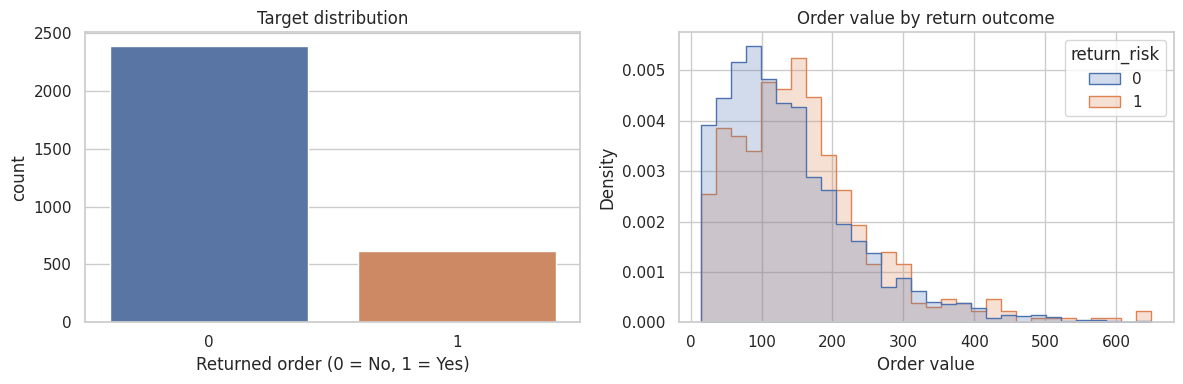

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=orders, x="return_risk", hue="return_risk", legend=False, ax=axes[0])
axes[0].set(title="Target distribution", xlabel="Returned order (0 = No, 1 = Yes)")
sns.histplot(data=orders, x="order_value", hue="return_risk",
             bins=30, element="step", stat="density", common_norm=False, ax=axes[1])
axes[1].set(title="Order value by return outcome", xlabel="Order value")
plt.tight_layout()
plt.show()

### 2.3 Define features and target

`order_id` is an identifier, not a predictive signal. We exclude it from the feature matrix. The target column is stored separately as `y`.

We also create the holdout test set now. Stratification preserves approximately the same target-class proportion in both partitions.

In [5]:
target = "return_risk"
identifier = "order_id"

X = orders.drop(columns=[target, identifier])
y = orders[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print(f"Training return rate: {y_train.mean():.1%}")
print(f"Test return rate: {y_test.mean():.1%}")

Training rows: 2400
Test rows: 600
Training return rate: 20.4%
Test return rate: 20.5%


## 3. Establish a baseline

A baseline provides a reference point. Without it, a model score has little meaning.

A `DummyClassifier` ignores the input features and follows a simple rule. Here, `most_frequent` always predicts the majority class. A useful model should improve on this simple reference, especially on the metrics that matter to the business.

In [6]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)

baseline_results = pd.Series({
    "Accuracy": accuracy_score(y_test, baseline_predictions),
    "Precision": precision_score(y_test, baseline_predictions, zero_division=0),
    "Recall": recall_score(y_test, baseline_predictions, zero_division=0),
    "F1": f1_score(y_test, baseline_predictions, zero_division=0)
})
baseline_results.to_frame("Baseline score")

,Baseline score
Accuracy,0.795
Precision,0.000
Recall,0.000
F1,0.000


### Knowledge check

1. Why can a majority-class classifier have reasonable accuracy but zero recall for the returned class?
2. Why should a model be compared with a baseline rather than judged by accuracy alone?
3. If missing a returned order is expensive, which metric deserves close attention?

**Instructor discussion:** Ask students to describe the operational consequence of a false negative and a false positive before choosing a metric.

## 4. Model complexity, underfitting, and overfitting

A model is **underfitting** when it is too simple to learn important patterns. It performs poorly on both training and validation data.

A model is **overfitting** when it learns details that are specific to the training sample, including noise. It performs very well on training data but noticeably worse on unseen data.

A model that generalizes well captures useful patterns without memorizing the training examples.

### 4.1 Compare decision-tree depth

A decision tree with unrestricted depth can create many narrow rules. Limiting `max_depth` controls its complexity. We compare training and cross-validation scores over several depths.

The validation scores are calculated only within the training partition. The test set remains untouched.

In [7]:
depth_values = [1, 2, 3, 4, 6, 8, 12, None]
depth_rows = []

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

for depth in depth_values:
    tree = DecisionTreeClassifier(
        max_depth=depth,
        min_samples_leaf=10,
        random_state=RANDOM_STATE
    )
    tree.fit(X_train.select_dtypes(include=np.number), y_train)
    train_score = tree.score(X_train.select_dtypes(include=np.number), y_train)
    cv_score = cross_validate(
        tree,
        X_train.select_dtypes(include=np.number),
        y_train,
        cv=cv_strategy,
        scoring="roc_auc",
        return_train_score=False
    )["test_score"].mean()
    depth_rows.append({
        "max_depth": "None" if depth is None else str(depth),
        "training_accuracy": train_score,
        "mean_cv_roc_auc": cv_score
    })

depth_results = pd.DataFrame(depth_rows)
display(depth_results)

,max_depth,training_accuracy,mean_cv_roc_auc
0,1,0.795833,0.574554
1,2,0.795833,0.592261
2,3,0.795833,0.619468
3,4,0.804167,0.622828
4,6,0.807917,0.608067
5,8,0.815833,0.579589
6,12,0.823333,0.559448
7,None,0.823333,0.562063


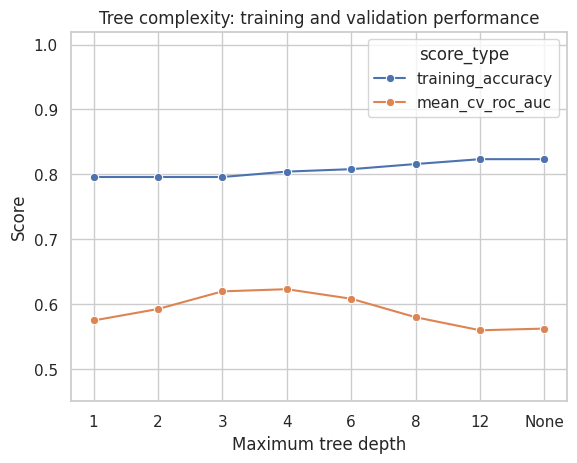

In [8]:
plot_data = depth_results.melt(
    id_vars="max_depth",
    value_vars=["training_accuracy", "mean_cv_roc_auc"],
    var_name="score_type",
    value_name="score"
)
sns.lineplot(data=plot_data, x="max_depth", y="score",
             hue="score_type", marker="o")
plt.title("Tree complexity: training and validation performance")
plt.xlabel("Maximum tree depth")
plt.ylabel("Score")
plt.ylim(0.45, 1.02)
plt.show()

**Interpretation**

- A shallow tree may miss useful relationships: underfitting.
- As depth increases, training performance usually improves.
- If validation performance stops improving or declines while training performance keeps rising, the tree is likely becoming too complex.
- The best depth is not necessarily the deepest tree.

The exact pattern depends on the dataset and the chosen metric. Use the validation evidence rather than assuming a fixed depth is always best.

### 4.2 Bias–variance trade-off

The **bias–variance trade-off** describes a common tension:

- High bias: the model makes restrictive assumptions and may underfit.
- High variance: the model is sensitive to the particular training sample and may overfit.

Increasing model complexity can reduce bias but may increase variance. The goal is not to minimize training error at any cost; it is to achieve reliable performance on new data.

### Exercise 1 — Diagnose model fit

Using `depth_results`:

1. Identify the depth with the highest mean cross-validation ROC-AUC.
2. Compare its training accuracy with its validation score.
3. Identify a setting that appears to underfit.
4. Explain why choosing the setting with the highest training accuracy would be unsafe.

Write your interpretation in 3–5 sentences before moving on.

## 5. Regularization: L1 and L2

Regularization discourages a model from relying too heavily on large coefficients. It is a way to control model complexity and reduce sensitivity to noise.

For logistic regression, scikit-learn's `C` parameter is the **inverse** of regularization strength:

- Smaller `C` means stronger regularization.
- Larger `C` means weaker regularization.

Two common penalties are:

- **L1 (Lasso-style):** can drive some coefficients to exactly zero, creating a sparse model.
- **L2 (Ridge-style):** shrinks coefficients toward zero but usually does not make them exactly zero.

Feature scaling is important for coefficient-based models. We will therefore scale numeric features inside a pipeline.

### 5.1 Prepare preprocessing steps

Numeric columns are imputed with their median and scaled. Categorical columns are imputed with the most frequent value and one-hot encoded.

Placing preprocessing inside a `Pipeline` ensures that each cross-validation fold learns imputation values, scaling parameters, and category encodings from its own training fold only. This helps prevent data leakage.

In [9]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_preprocessor, numeric_features),
    ("categorical", categorical_preprocessor, categorical_features)
])

### 5.2 Compare L1 and L2 regularization

We evaluate several `C` values with stratified cross-validation. The same folds are used for every candidate so that the comparison is fair.

In [10]:
regularization_rows = []

for penalty in ["l1", "l2"]:
    for c_value in [0.01, 0.1, 1, 10, 100]:
        model = Pipeline(steps=[
            ("preprocess", preprocessor),
            ("classifier", LogisticRegression(
                penalty=penalty,
                C=c_value,
                solver="liblinear",
                max_iter=2000,
                random_state=RANDOM_STATE
            ))
        ])
        scores = cross_validate(
            model, X_train, y_train,
            cv=cv_strategy,
            scoring={"roc_auc": "roc_auc", "f1": "f1", "recall": "recall"},
            n_jobs=-1
        )
        regularization_rows.append({
            "penalty": penalty,
            "C": c_value,
            "mean_roc_auc": scores["test_roc_auc"].mean(),
            "std_roc_auc": scores["test_roc_auc"].std(),
            "mean_f1": scores["test_f1"].mean(),
            "mean_recall": scores["test_recall"].mean()
        })

regularization_results = pd.DataFrame(regularization_rows)
display(regularization_results.sort_values("mean_roc_auc", ascending=False))

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is 

/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is 

/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is 

,penalty,C,mean_roc_auc,std_roc_auc,mean_f1,mean_recall
6,l2,0.10,0.670365,0.024360,0.079812,0.042857
1,l1,0.10,0.670360,0.029008,0.043377,0.022449
7,l2,1.00,0.669826,0.023996,0.097317,0.053061
3,l1,10.00,0.669815,0.023868,0.097079,0.053061
2,l1,1.00,0.669810,0.024550,0.093821,0.051020
8,l2,10.00,0.669751,0.023943,0.097079,0.053061
4,l1,100.00,0.669719,0.023928,0.097079,0.053061
9,l2,100.00,0.669714,0.023922,0.097079,0.053061
5,l2,0.01,0.669297,0.027122,0.027762,0.014286
0,l1,0.01,0.631667,0.035651,0.000000,0.000000


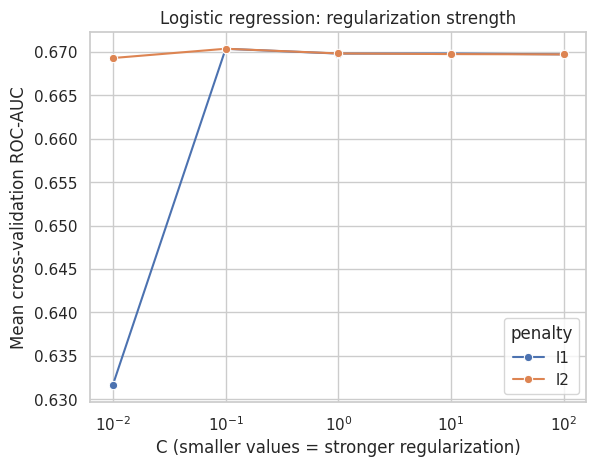

In [11]:
sns.lineplot(
    data=regularization_results,
    x="C", y="mean_roc_auc",
    hue="penalty", marker="o"
)
plt.xscale("log")
plt.title("Logistic regression: regularization strength")
plt.xlabel("C (smaller values = stronger regularization)")
plt.ylabel("Mean cross-validation ROC-AUC")
plt.show()

### 5.3 Inspect coefficient sparsity

After fitting an L1-regularized logistic regression model, count how many coefficients are non-zero. L1 may remove some encoded features from the model. The coefficient values are tied to the scaled and encoded feature representation, so interpret them with care.

In [12]:
l1_pipeline = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("classifier", LogisticRegression(
        penalty="l1", C=0.1, solver="liblinear",
        max_iter=2000, random_state=RANDOM_STATE
    ))
])
l1_pipeline.fit(X_train, y_train)

encoded_names = l1_pipeline.named_steps["preprocess"].get_feature_names_out()
coefficients = l1_pipeline.named_steps["classifier"].coef_.ravel()

coefficient_table = pd.DataFrame({
    "feature": encoded_names,
    "coefficient": coefficients
})
coefficient_table["absolute_coefficient"] = coefficient_table["coefficient"].abs()
print("Non-zero coefficients:", int((coefficients != 0).sum()), "of", len(coefficients))
display(coefficient_table.sort_values("absolute_coefficient", ascending=False).head(12))

Non-zero coefficients: 9 of 16


/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


,feature,coefficient,absolute_coefficient
1,numeric__items_count,0.458217,0.458217
3,numeric__delivery_days,0.238581,0.238581
13,categorical__product_category_Accessories,-0.214651,0.214651
2,numeric__discount_rate,0.209947,0.209947
0,numeric__order_value,0.165543,0.165543
15,categorical__product_category_Home,-0.115541,0.115541
5,numeric__customer_tenure_months,-0.114570,0.114570
12,categorical__shipping_type_Standard,-0.069424,0.069424
4,numeric__customer_orders,-0.056345,0.056345
6,categorical__payment_method_Bank Transfer,0.000000,0.000000


### Exercise 2 — Regularization decisions

1. Explain the meaning of a small `C` value in logistic regression.
2. Which penalty can set coefficients exactly to zero?
3. Why is scaling applied inside the pipeline?
4. If two models have similar cross-validation scores, what other considerations might influence your choice?

**Practical task:** Change the `C` values and compare the number of non-zero coefficients with mean validation ROC-AUC. Record the trade-off you observe.

## 6. Build leakage-safe modeling pipelines

A pipeline combines preprocessing and an estimator into one object. This is especially important when using cross-validation or hyperparameter search.

The pipeline is fitted separately on each training fold. The corresponding validation fold is transformed using only the preprocessing learned from that fold's training data.

This approach also makes the final workflow easier to reproduce and deploy.

### 6.1 Define candidate model families

We will compare models with different assumptions and levels of complexity:

- Logistic Regression: a linear decision boundary and interpretable coefficients.
- Decision Tree: rule-based splits that can model non-linear patterns.
- Random Forest: an ensemble of trees that reduces the instability of a single tree.
- Extra Trees: randomized tree splits that provide another ensemble approach.

All models use the same preprocessing structure. Tree models do not require feature scaling, but retaining a consistent pipeline makes the comparison workflow easier to manage.

In [13]:
candidate_models = {
    "Logistic Regression": LogisticRegression(
        C=1.0, max_iter=2000, random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5, min_samples_leaf=10, random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=250, min_samples_leaf=5,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=250, min_samples_leaf=5,
        random_state=RANDOM_STATE, n_jobs=-1
    )
}

candidate_pipelines = {
    name: Pipeline(steps=[
        ("preprocess", preprocessor),
        ("classifier", estimator)
    ])
    for name, estimator in candidate_models.items()
}

## 7. Compare candidate models with cross-validation

A single train/validation split can produce a result that depends strongly on which observations happened to be selected. Cross-validation repeats the evaluation across multiple folds.

We use **Stratified K-Fold** because this is a classification problem. It aims to preserve the class proportions in each fold.

We will report ROC-AUC, average precision, precision, recall, and F1. No single metric tells the whole story:

- ROC-AUC measures ranking quality across classification thresholds.
- Average precision summarizes the precision–recall curve and is useful when the positive class is less common.
- Precision measures how many predicted returns were actual returns.
- Recall measures how many actual returns were detected.
- F1 balances precision and recall through their harmonic mean.

In [14]:
scoring_metrics = {
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

comparison_rows = []
comparison_objects = {}

for name, pipeline in candidate_pipelines.items():
    cv_result = cross_validate(
        pipeline,
        X_train, y_train,
        cv=cv_strategy,
        scoring=scoring_metrics,
        return_train_score=True,
        n_jobs=-1
    )
    comparison_objects[name] = cv_result
    comparison_rows.append({
        "model": name,
        "roc_auc_mean": cv_result["test_roc_auc"].mean(),
        "roc_auc_std": cv_result["test_roc_auc"].std(),
        "average_precision_mean": cv_result["test_average_precision"].mean(),
        "precision_mean": cv_result["test_precision"].mean(),
        "recall_mean": cv_result["test_recall"].mean(),
        "f1_mean": cv_result["test_f1"].mean(),
        "train_roc_auc_mean": cv_result["train_roc_auc"].mean()
    })

model_comparison = pd.DataFrame(comparison_rows).sort_values(
    "roc_auc_mean", ascending=False
).reset_index(drop=True)

display(model_comparison.round(3))

/opt/pyvenv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/pyvenv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/pyvenv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


,model,roc_auc_mean,roc_auc_std,average_precision_mean,precision_mean,recall_mean,f1_mean,train_roc_auc_mean
0,Logistic Regression,0.670,0.024,0.354,0.634,0.053,0.097,0.683
1,Random Forest,0.648,0.033,0.335,0.453,0.016,0.031,0.976
2,Extra Trees,0.631,0.033,0.311,0.200,0.004,0.008,0.952
3,Decision Tree,0.617,0.016,0.288,0.449,0.082,0.134,0.727


<Figure size 1000x500 with 0 Axes>

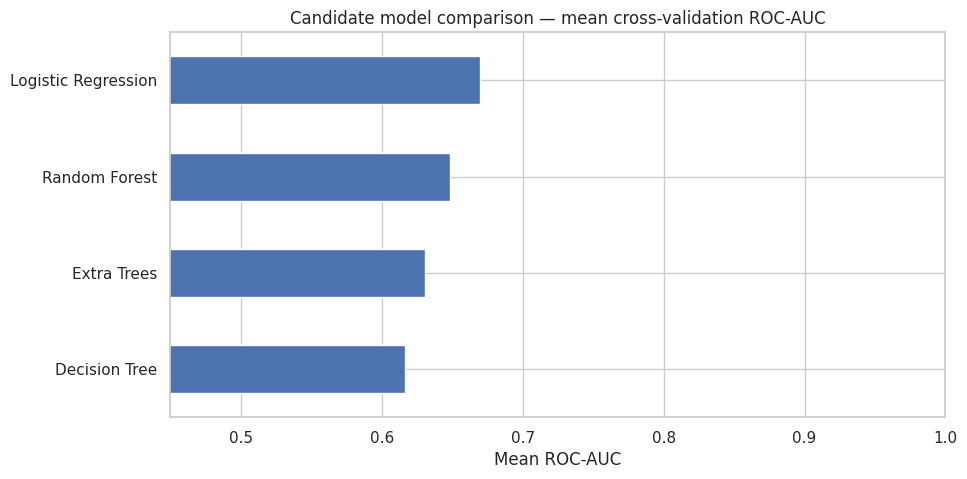

In [15]:
plt.figure(figsize=(10, 5))
model_comparison.sort_values("roc_auc_mean").plot.barh(x="model", y="roc_auc_mean", legend=False, figsize=(10, 5))
plt.xlim(0.45, 1.0)
plt.title("Candidate model comparison — mean cross-validation ROC-AUC")
plt.xlabel("Mean ROC-AUC")
plt.ylabel("")
plt.show()

### 7.1 Consider stability, not only the mean

The standard deviation across folds provides a simple view of score variability. A slightly higher mean score may not be worth choosing if its results vary much more between folds.

Also compare training and validation scores. A large gap can indicate overfitting. These are diagnostic signals, not automatic rules.

### Exercise 3 — Make a shortlist

Use `model_comparison` to answer:

1. Which model has the highest mean ROC-AUC?
2. Which model has the highest mean recall?
3. Which model has the smallest ROC-AUC standard deviation?
4. Is there a large gap between training and validation ROC-AUC for any model?
5. Recommend two candidates for further tuning and justify your choice using at least two metrics.

Do not select a model using only one metric.

## 8. Hyperparameter optimization

A **parameter** is learned from the training data. For example, logistic regression learns its coefficients.

A **hyperparameter** is set before fitting and controls how the learning algorithm behaves. Examples include tree depth, number of trees, and regularization strength.

Hyperparameter search evaluates candidate settings using cross-validation. The search must run on the training data only. The held-out test set remains reserved for final evaluation.

### 8.1 Grid search

`GridSearchCV` evaluates every combination in the parameter grid. It is useful when the search space is small and deliberately chosen.

In [16]:
logistic_pipeline = candidate_pipelines["Logistic Regression"]

logistic_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__penalty": ["l1", "l2"],
    "classifier__solver": ["liblinear"]
}

logistic_search = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=logistic_grid,
    scoring="roc_auc",
    cv=cv_strategy,
    n_jobs=-1,
    refit=True,
    return_train_score=True
)
logistic_search.fit(X_train, y_train)

print("Best CV ROC-AUC:", round(logistic_search.best_score_, 4))
print("Best parameters:", logistic_search.best_params_)

/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is 

/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is 

Best CV ROC-AUC: 0.6704
Best parameters: {'classifier__C': 0.1, 'classifier__penalty': 'l2', 'classifier__solver': 'liblinear'}


In [17]:
grid_results = pd.DataFrame(logistic_search.cv_results_)
display(
    grid_results[
        ["param_classifier__C", "param_classifier__penalty",
         "mean_test_score", "std_test_score", "mean_train_score", "rank_test_score"]
    ].sort_values("rank_test_score").head(10)
)

,param_classifier__C,param_classifier__penalty,mean_test_score,std_test_score,mean_train_score,rank_test_score
3,0.10,l2,0.670365,0.024360,0.682640,1
2,0.10,l1,0.670360,0.029008,0.678985,2
5,1.00,l2,0.669826,0.023996,0.683076,3
6,10.00,l1,0.669815,0.023868,0.683080,4
4,1.00,l1,0.669810,0.024550,0.682871,5
7,10.00,l2,0.669751,0.023943,0.683076,6
8,100.00,l1,0.669719,0.023928,0.683082,7
9,100.00,l2,0.669714,0.023922,0.683084,8
1,0.01,l2,0.669297,0.027122,0.678302,9
0,0.01,l1,0.631667,0.035651,0.631513,10


### 8.2 Randomized search

`RandomizedSearchCV` samples a fixed number of parameter combinations instead of testing every possible combination. It is often more efficient when the search space is large.

We will tune a Random Forest using a defined search budget. A fixed random state makes the sampled candidates reproducible.

In [18]:
forest_pipeline = candidate_pipelines["Random Forest"]

forest_distributions = {
    "classifier__n_estimators": randint(150, 501),
    "classifier__max_depth": [None, 4, 6, 8, 12, 16],
    "classifier__min_samples_split": randint(2, 16),
    "classifier__min_samples_leaf": randint(2, 12),
    "classifier__max_features": ["sqrt", "log2", None]
}

forest_search = RandomizedSearchCV(
    estimator=forest_pipeline,
    param_distributions=forest_distributions,
    n_iter=18,
    scoring="roc_auc",
    cv=cv_strategy,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    refit=True,
    return_train_score=True
)
forest_search.fit(X_train, y_train)

print("Best CV ROC-AUC:", round(forest_search.best_score_, 4))
print("Best parameters:")
display(pd.Series(forest_search.best_params_, name="value").to_frame())

Best CV ROC-AUC: 0.6646
Best parameters:


,value
classifier__max_depth,4
classifier__max_features,log2
classifier__min_samples_leaf,5
classifier__min_samples_split,15
classifier__n_estimators,500


### 8.3 Compare tuned candidates

The search objects retain the best estimator fitted on the full training partition. We compare their best cross-validation scores with the earlier candidate results.

The highest score is useful evidence, but it is not the only selection criterion. Consider stability, interpretability, training time, inference requirements, and the cost of errors.

In [19]:
tuned_summary = pd.DataFrame([
    {"model": "Tuned Logistic Regression", "best_cv_roc_auc": logistic_search.best_score_},
    {"model": "Tuned Random Forest", "best_cv_roc_auc": forest_search.best_score_}
]).sort_values("best_cv_roc_auc", ascending=False)

display(tuned_summary.round(4))

,model,best_cv_roc_auc
0,Tuned Logistic Regression,0.6704
1,Tuned Random Forest,0.6646


### 8.4 Why nested cross-validation may be needed

When the same cross-validation results are used both to search many hyperparameter settings and to report the selected model's performance, the reported best score can be optimistic. The search has selected the setting that performed best on those particular folds.

**Nested cross-validation** separates these roles:

- Inner cross-validation selects hyperparameters.
- Outer cross-validation estimates the performance of the complete selection procedure.

Nested cross-validation is valuable when a robust performance estimate is required and sufficient data and computing time are available. In this workshop, we use a separate untouched test set for the final evaluation instead.

## 9. Select and evaluate the final model

### 9.1 Define a selection rule

Model selection should reflect the problem, not just a leaderboard. For this workshop, we will:

1. use cross-validation ROC-AUC as the primary ranking metric;
2. inspect average precision, recall, F1, and fold-to-fold variation;
3. consider interpretability and operational complexity;
4. choose one tuned candidate before opening the test results.

The next cell selects the candidate with the higher best cross-validation ROC-AUC. In a production project, the team should document and approve the selection rule before reviewing the final test metrics.

In [20]:
final_candidates = {
    "Tuned Logistic Regression": logistic_search,
    "Tuned Random Forest": forest_search
}

selected_name = max(
    final_candidates,
    key=lambda name: final_candidates[name].best_score_
)
final_model = final_candidates[selected_name].best_estimator_

print("Selected model:", selected_name)
print("Selection CV ROC-AUC:", round(final_candidates[selected_name].best_score_, 4))

Selected model: Tuned Logistic Regression
Selection CV ROC-AUC: 0.6704


### 9.2 Evaluate once on the holdout test set

The selected pipeline is now evaluated on the test set, which was not used for preprocessing decisions, candidate comparison, or hyperparameter search.

This is the first and final use of the test set in this notebook. Treat these results as the best available estimate of performance on similar unseen data, not a guarantee of future business outcomes.

In [21]:
test_probabilities = final_model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= 0.50).astype(int)

final_metrics = pd.Series({
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Precision": precision_score(y_test, test_predictions, zero_division=0),
    "Recall": recall_score(y_test, test_predictions, zero_division=0),
    "F1": f1_score(y_test, test_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_probabilities),
    "Average Precision": average_precision_score(y_test, test_probabilities)
}, name="Test score")

display(final_metrics.to_frame().round(3))

,Test score
Accuracy,0.807
Precision,0.818
Recall,0.073
F1,0.134
ROC-AUC,0.652
Average Precision,0.392


              precision    recall  f1-score   support

Not returned       0.81      1.00      0.89       477
    Returned       0.82      0.07      0.13       123

    accuracy                           0.81       600
   macro avg       0.81      0.53      0.51       600
weighted avg       0.81      0.81      0.74       600



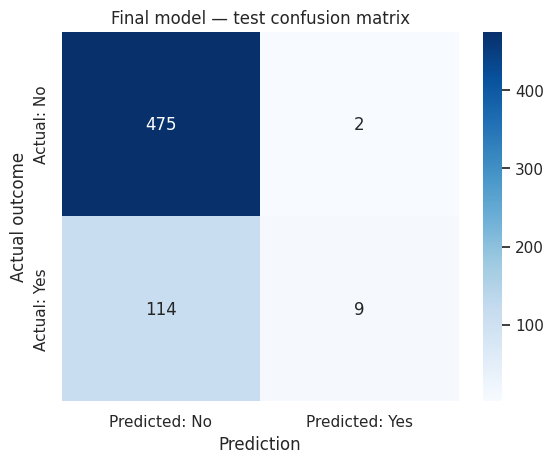

In [22]:
print(classification_report(
    y_test, test_predictions,
    target_names=["Not returned", "Returned"],
    zero_division=0
))

cm = confusion_matrix(y_test, test_predictions)
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Predicted: No", "Predicted: Yes"],
    yticklabels=["Actual: No", "Actual: Yes"]
)
plt.title("Final model — test confusion matrix")
plt.xlabel("Prediction")
plt.ylabel("Actual outcome")
plt.show()

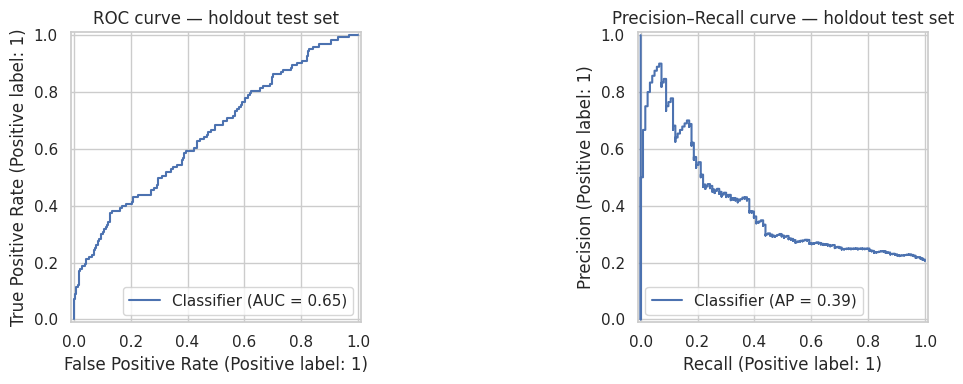

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
RocCurveDisplay.from_predictions(y_test, test_probabilities, ax=axes[0])
axes[0].set_title("ROC curve — holdout test set")
PrecisionRecallDisplay.from_predictions(y_test, test_probabilities, ax=axes[1])
axes[1].set_title("Precision–Recall curve — holdout test set")
plt.tight_layout()
plt.show()

## 10. Turn model scores into operational decisions

Most classifiers produce a probability or score. A threshold converts that score into a class label.

At the default threshold of 0.50:

- scores at or above 0.50 are classified as returned;
- scores below 0.50 are classified as not returned.

The best threshold depends on the cost of false positives and false negatives. If missing a returned order is more expensive than reviewing an order that would not be returned, the business may prefer a lower threshold and higher recall.

**Important:** A threshold should be selected using validation data or cross-validated predictions, not by repeatedly optimizing against the test set. For this workshop, the next analysis is a demonstration of the trade-off on the holdout data; do not use it to revise the final model's reported test score.

In [24]:
thresholds = np.arange(0.20, 0.81, 0.05)
threshold_rows = []

for threshold in thresholds:
    predictions_at_threshold = (test_probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, predictions_at_threshold).ravel()
    threshold_rows.append({
        "threshold": threshold,
        "precision": precision_score(y_test, predictions_at_threshold, zero_division=0),
        "recall": recall_score(y_test, predictions_at_threshold, zero_division=0),
        "f1": f1_score(y_test, predictions_at_threshold, zero_division=0),
        "false_positives": fp,
        "false_negatives": fn
    })

threshold_analysis = pd.DataFrame(threshold_rows)
display(threshold_analysis.round(3))

,threshold,precision,recall,f1,false_positives,false_negatives
0,0.20,0.264,0.634,0.372,218,45
1,0.25,0.295,0.504,0.372,148,61
2,0.30,0.375,0.390,0.382,80,75
3,0.35,0.452,0.268,0.337,40,90
4,0.40,0.622,0.187,0.288,14,100
5,0.45,0.737,0.114,0.197,5,109
6,0.50,0.818,0.073,0.134,2,114
7,0.55,0.800,0.033,0.062,1,119
8,0.60,0.750,0.024,0.047,1,120
9,0.65,0.000,0.000,0.000,1,123


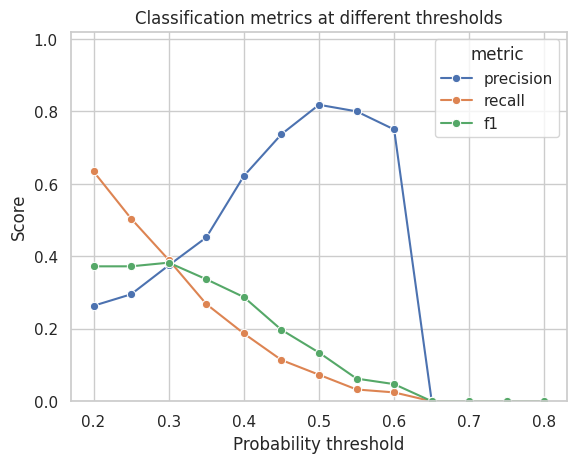

In [25]:
threshold_plot = threshold_analysis.melt(
    id_vars="threshold",
    value_vars=["precision", "recall", "f1"],
    var_name="metric",
    value_name="score"
)
sns.lineplot(data=threshold_plot, x="threshold", y="score",
             hue="metric", marker="o")
plt.title("Classification metrics at different thresholds")
plt.xlabel("Probability threshold")
plt.ylabel("Score")
plt.ylim(0, 1.02)
plt.show()

### 10.1 A simple business-cost exercise

Assume the operations team estimates:

- reviewing an order flagged by the model costs 4 currency units;
- failing to identify an order that is eventually returned costs 35 currency units.

For this simplified exercise, total cost is:

`review cost × (TP + FP) + missed-return cost × FN`

This is not a complete financial model. It assumes each flagged order receives one review and that the costs are fixed. Real business costs should be estimated with stakeholders and validated against operational data.

In [26]:
REVIEW_COST = 4
MISSED_RETURN_COST = 35

cost_rows = []
for row in threshold_analysis.itertuples(index=False):
    predicted = (test_probabilities >= row.threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, predicted).ravel()
    total_cost = REVIEW_COST * (tp + fp) + MISSED_RETURN_COST * fn
    cost_rows.append({
        "threshold": row.threshold,
        "reviewed_orders": tp + fp,
        "missed_returns": fn,
        "estimated_total_cost": total_cost
    })

cost_analysis = pd.DataFrame(cost_rows)
display(cost_analysis.sort_values("estimated_total_cost").round(2))

,threshold,reviewed_orders,missed_returns,estimated_total_cost
0,0.20,296,45,2759
1,0.25,210,61,2975
2,0.30,128,75,3137
3,0.35,73,90,3442
4,0.40,37,100,3648
5,0.45,19,109,3891
6,0.50,11,114,4034
7,0.55,5,119,4185
8,0.60,4,120,4216
11,0.75,0,123,4305


### Exercise 4 — Recommend an operating threshold

Using the threshold and cost tables:

1. Identify the threshold with the lowest estimated total cost under the stated assumptions.
2. Compare its recall with the default 0.50 threshold.
3. Explain the operational impact of increasing the number of flagged orders.
4. List two additional costs or constraints that should be discussed before deployment.

Do not describe the lowest-cost threshold in this synthetic exercise as a production-ready setting.

## 11. Applied workshop challenge

# AdventureWorks — Return Risk Model Review

### Scenario

You are a junior machine learning engineer supporting the AdventureWorks operations team. The team needs a clear recommendation for a model that can help prioritize orders for manual review.

Your task is to complete a compact model selection exercise and present the evidence behind your recommendation.

### Required tasks

**Part A — Establish the problem**

1. State the prediction target and the business purpose.
2. Identify the positive class.
3. Explain why accuracy alone may be insufficient.

**Part B — Compare models**

1. Add at least one additional candidate model.
2. Evaluate it with the same stratified cross-validation strategy.
3. Compare ROC-AUC, average precision, recall, F1, and score variability.
4. Explain whether the new model should join the shortlist.

**Part C — Regularization and tuning**

1. Tune at least two meaningful hyperparameters.
2. Explain how the selected settings affect model complexity.
3. Keep all preprocessing inside a pipeline.

**Part D — Final evaluation**

1. Select one model using training-only validation evidence.
2. Evaluate it once on the held-out test set.
3. Report the confusion matrix and at least four classification metrics.
4. Explain the main error type that concerns the business.

**Part E — Business recommendation**

Write a short recommendation for the operations manager. Include:

- selected model and reason for selection;
- test-set performance;
- proposed threshold considerations;
- key limitations;
- next steps before a pilot.

### Submission standard

Submit the completed notebook with executed outputs and a concise recommendation (approximately 250–400 words). Every chart and metric must have a clear interpretation. A high score without a defensible explanation is not a complete solution.

### Challenge starter — add another candidate

Use the following starter code to evaluate a Decision Tree with a different complexity setting. You may replace it with another estimator covered in the course.

In [27]:
# Starter: evaluate an additional model using the same validation protocol.
additional_pipeline = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=8,
        min_samples_leaf=15,
        random_state=RANDOM_STATE
    ))
])

additional_scores = cross_validate(
    additional_pipeline,
    X_train, y_train,
    cv=cv_strategy,
    scoring=scoring_metrics,
    n_jobs=-1
)

pd.Series({
    metric: additional_scores[f"test_{metric}"].mean()
    for metric in scoring_metrics
}, name="Additional model — mean CV score").to_frame()

,Additional model — mean CV score
roc_auc,0.584218
average_precision,0.270741
precision,0.349569
recall,0.120408
f1,0.173125


## 12. Summary and readiness checklist

### Key takeaways

- Model selection is a structured comparison process, not a search for the highest training score.
- A baseline provides context for interpreting model performance.
- Underfitting and overfitting describe different generalization problems.
- Regularization controls model complexity; for logistic regression, smaller `C` means stronger regularization.
- L1 can produce sparse coefficients, while L2 shrinks coefficients.
- Pipelines help keep preprocessing inside each cross-validation fold and reduce leakage risk.
- Cross-validation provides a more stable comparison than one validation split.
- Grid search is exhaustive over a defined grid; randomized search samples a fixed number of candidates.
- Hyperparameter selection and final performance estimation should use separate data.
- A probability threshold should reflect business costs and operational capacity.

### Readiness checklist

Before moving to the next stage, confirm that you can:

- [ ] explain the difference between a parameter and a hyperparameter;
- [ ] recognize signs of underfitting and overfitting;
- [ ] explain the purpose of L1 and L2 regularization;
- [ ] build a preprocessing and model pipeline;
- [ ] compare models using stratified cross-validation;
- [ ] tune a model with `GridSearchCV` or `RandomizedSearchCV`;
- [ ] keep the test set separate until final evaluation;
- [ ] interpret precision, recall, F1, ROC-AUC, and average precision;
- [ ] explain how threshold changes affect business decisions;
- [ ] communicate a model recommendation with limitations.

### Further reading

- [Scikit-learn — Model selection and evaluation](https://scikit-learn.org/stable/model_selection.html)
- [Scikit-learn — Cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html)
- [Scikit-learn — Pipeline and composite estimators](https://scikit-learn.org/stable/modules/compose.html)
- [Scikit-learn — Logistic regression](https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression)
- [Scikit-learn — Classification metrics](https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics)

---

**End of Notebook 14 — Model Selection, Regularization & Applied ML Workshop**